In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent    # notebooks -> project_root
sys.path.insert(0, str(project_root))
print(project_root)

import numpy as np

from mpi4py import MPI
from dolfinx import fem, mesh

from BaseModels import GaussianLikelihood
from FenicsxModels.FenicsxPriors import MultiFieldPrior
from FenicsxModels.PAISolver import PAISolver
from FenicsxModels import Helpers


/Users/tcui0786/Work/DeepTransport/PyFInS


# Set up acoustic wave solver #

Acoustic forward problem is solved in $\Omega = [0,4] \times [0,2]$ using a Newmark scheme. 
\begin{align*}
p_{tt} - c^2 \Delta p &= 0 \quad \mathrm{in } \Omega \times (0,T] \\
p(t=0) &= p_0 \quad \mathrm{in } \Omega \\
p_t(t=0) &= 0 \quad \mathrm{in } \Omega \\
\nabla p \cdot \mathbf{n} + \frac{1}{c}p_t &= 0 \quad \mathrm{on } \partial\Omega \times (0,T]
\end{align*}

# Optic PDE
Relates the unknown absorption coefficient $\mu_a(\mathbf{m},\lambda)$ to the light fluence $\phi$ in $\Omega = [0,5] \times [0,3]$
\begin{align*}
\mu_a \phi - \nabla \cdot (\kappa(\mu_a) \nabla \phi ) &= 0 \quad \text{ in } \Omega, \\
\frac{1}{\pi}\phi + \frac{1}{2}\kappa(\mu_a)\nabla \phi\cdot \mathbf{n} &= s(x_c) \quad \text{ on } \partial \Omega.
\end{align*}
Here, the source term $s(x_c) = \exp\left(-\frac{(x-x_c)^2}{2\sigma_s^2}\right)\chi(y_i)$ is on the top ($y_i = 2.0$) or bottom ($y_i = 0.0$) boundary. The center of the bump can be an additional design variable.

The absorption coefficient is a function of the total hemoglobin concentration ($c_{HbT}$) and oxygenated tissue ratio ($s$). It also depends on the laser wavelength $\lambda \in [650,1000]$ through the molar extinction coefficient of oxygenated and deoxygenated blood ($\epsilon_{o}$ and $\epsilon_{d}$, respectively):
$$ \mu_a(\mathbf{m},\lambda) = c_{HbT}(m_1)(s(m_2)\epsilon_{o}(\lambda) + (1.0 - s(m_2))\epsilon{d}(\lambda)).$$
Values for $\epsilon_{X}$ are taken from https://omlc.org/spectra/hemoglobin/summary.html and tabulated in molar_coefficients.py. 

The diffusion $\kappa$ is related to $\mu_a$ as:
$$ \kappa(\mu_a,\lambda) = \frac{1}{2(\mu_a(\lambda)+\mu'_s(\lambda))},
$$
where the reduced scattering coefficient is assumed to follow Jacques' power law (https://omlc.org/news/dec14/Jacques_PMB2013/index.html) with $a$ and $b$ defaulted to ``other tissue'':
$$
\mu'_s(\lambda) = a\big(\frac{\lambda}{\lambda_r}\big)^{-b}.
$$

# Summary of parameters #
| **Variable** | **Description** | **Unit** |
|---|---|---|
| $\lambda$ | wavelength | nm |
| $c_{HbT}$ | total hemoglobin concentration | $\mu\mathrm{M}$ (micromoles per liter) |
| $\epsilon_X$ | molar extinction coefficient | $\mathrm{cm}^{-1}\,\mu\mathrm{M}$ |
| $s$ | oxy to deoxy ratio | Unitless |



# Full coupled PDE and designs

The full observation model is given by
$$
\mathbf{y}(\mathbf{m},x_c,\lambda) = O(x_c) F G(\mathbf{m},\lambda,x_c), 
$$
where $G(\mathbf{m},\lambda)$ outputs $p_0 = \mu_a(\mathbf{m},\lambda,x_c)\phi(\mathbf{m},\lambda,x_i)$ through solving the optic PDE. $F$ solves the acoustic PDE and outputs the state $p$.

Observables are values of the state $p$ recorded at one probe located at the top or bottom boundary at $x_c \in [0,4]$.
At each probe, $n_T$ measurements are given, averaged over time range gates
$T_k = [t_{k-1}, t_k]$, $k = 1,\ldots,n_T$, that partition $(0,T]$:
$$ y_{k} \;=\; \frac{1}{|T_k|}\int_{T_k} p(t,{x}_c)\, dt.$$

# QoI 
There are a few options for the quantity of interest.
 <ol>
  <li>**sO2**  = $\frac{\int_R c_{HbT}s \, \mathrm{d}x}{\int_R c_{HbT}\, \mathrm{d}x}$ (hemoglobin-weighted sO2 in region-of-interest R) </li>
  <li>**HF** = $\frac{\int_{\Omega} c_{HbT}\chi(s < s_{t}) \, \mathrm{d}x}{\int_{\Omega} c_{HbT}\, \mathrm{d}x}$ (hemoglobin-weighted hypoxic fraction)</li>
  <li>**vsO2** = $\frac{\int_{\Omega} c_{HbT}s\chi(c_{HbT} > c_t) \, \mathrm{d}x}{\int_{\Omega} c_{HbT}\chi(c_{HbT} > c_t)\, \mathrm{d}x}$ (sO2 in high $c_{HbT}$ regions) </li>
</ol> 

Default is sO2, specified in PAIModel.apply_QoI


In [2]:
N = 32

domain = mesh.create_rectangle(
    MPI.COMM_WORLD,
    ((0.0, 0.0), (4.0, 2.0)),
    (N*2, N),
    cell_type=mesh.CellType.triangle,
)

Vh = fem.functionspace(domain, ("CG", 1))

# Time steps for acoustic wave eqn #
t_init, t_final, dt = 0.0, 30e-6, 5e-8
simulation_times = np.arange(t_init, t_final + 0.5*dt, dt)

wavelength=800.0
n_gates=20

roi = lambda x: np.where(((x[0]-3.0)**2)/(0.5**2)+((x[1]-1.0)**2)/(0.3**2) <= 1.0, 1.0, 0.0) # Region of interest for sO2 QoI

solver = PAISolver(
    domain,
    Vh,
    simulation_times,
    wavelength=wavelength,
    roi=roi,
    n_gates=n_gates,
    design_probe=False,
    xs_default=2.0,
    probe_y=2.0,
    qoi_type="sO2",
    high_accuracy=True, # turn off for reducing Krylov solves
    acoustic_check_tolerance=1.0e-8,
)

Acoustic observation operator: relative check error=1.861897e-10, passed=True


# Prior
The unknown parameter vector is $\mathbf{m} = [m_1,m_2]$. Both $m_1$ and $m_2$ apriori follow a Gaussian distribution,
\begin{align*}
c_{HbT}(m_1) &= \exp(m_1), \quad m_1 \sim \mathcal{N}(\overline{m}_1,C(\gamma_1,\delta_1)), \\
s(m_2) &= \frac{1}{1+\exp{-m_2}}, \quad m_2 \sim \mathcal{N}(\overline{m}_2,C(\gamma_2,\delta_2)), 
\end{align*}
with $C(\gamma,\delta) = A^{-2}$, with $A$ defined via the operator $\gamma \Delta + \delta I$.

In [3]:
rho = 0.5

correlation = np.array([
    [1.0, rho],
    [rho, 1.0],
])

prior = MultiFieldPrior(
    Vh,
    sigma=[0.25, 1.0],
    ell=[0.25, 0.25],
    mu=[np.log(25.0), np.log(0.7/0.3)],
    correlation=correlation,
    names=["cHbT", "sO2"],
    seed=12345,
)

In [4]:
sigma_obs = 0.2
like = GaussianLikelihood(np.zeros(solver.n_data), sigma=sigma_obs)

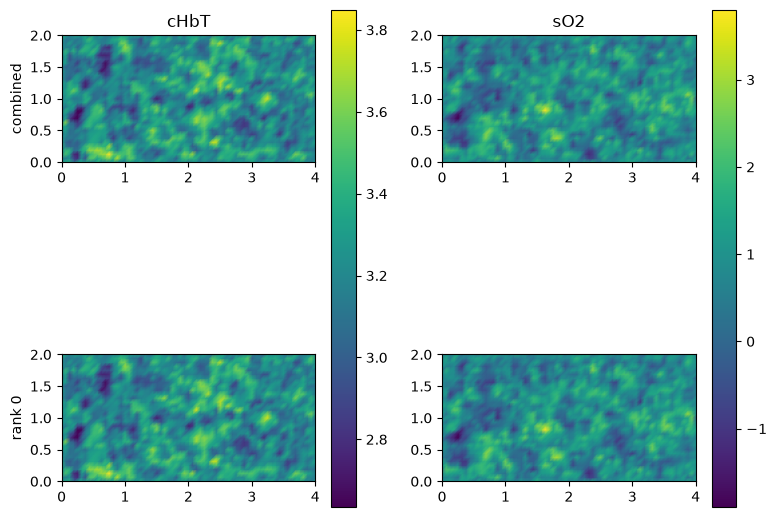

In [ ]:
m = prior.sample()
Helpers.plot_prior_draw_mpi(
    prior,
    m,
    filename=None,
    show=True,
)

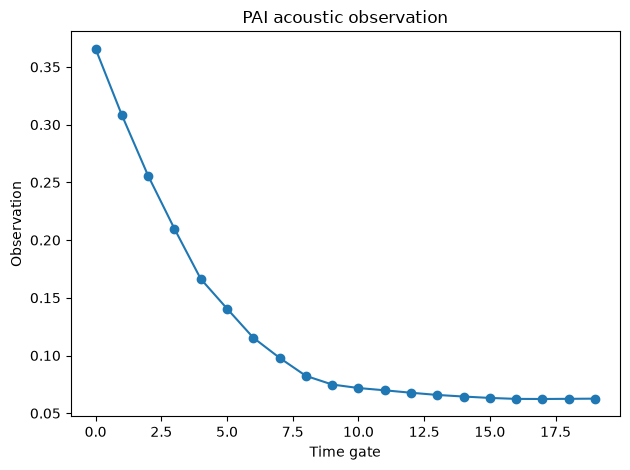

0.7162638477087971


In [6]:

import matplotlib.pyplot as plt

Y, Q = solver.solve(m)

Y_plot = Y.reshape(solver.observation.n_sensors, solver.observation.n_gates)
fig, ax = plt.subplots()
for i in range(solver.observation.n_sensors):
    ax.plot(
        np.arange(solver.observation.n_gates),
        Y_plot[i],
        marker="o",
        label=f"sensor {i}",
    )

ax.set_xlabel("Time gate")
ax.set_ylabel("Observation")
ax.set_title("PAI acoustic observation")

if solver.observation.n_sensors > 1:
    ax.legend()

fig.tight_layout()
plt.show()

print(Q)

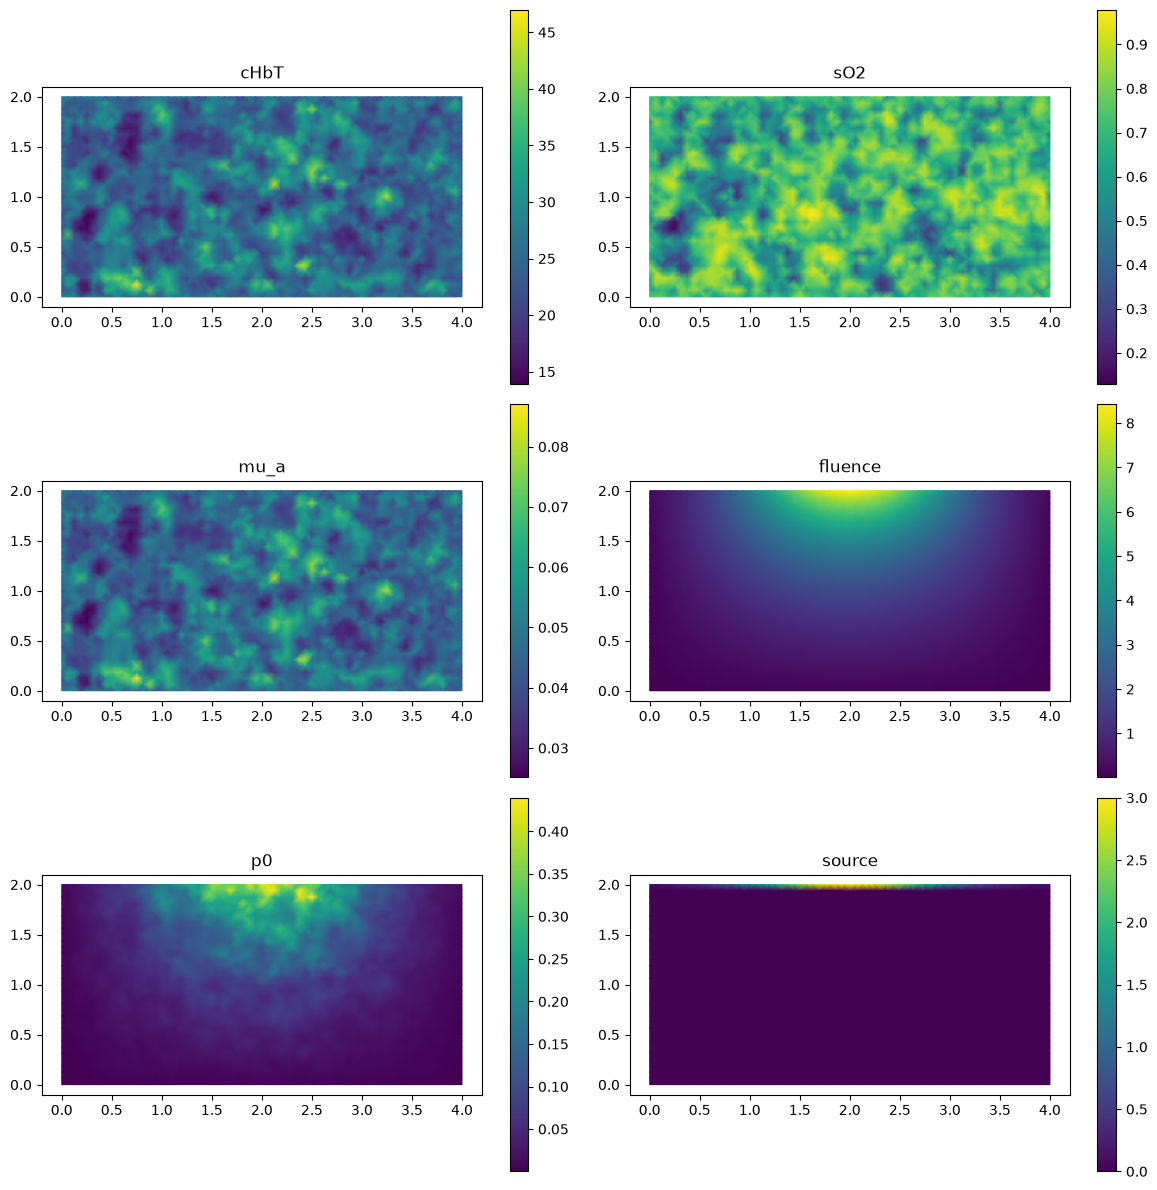

In [7]:
solver.optical.plot_solution()